# 02. E0 — бейзлайн: LightGBM на ручных признаках

**Что делаем:** строим сильный воспроизводимый бейзлайн, с которым потом сравниваем автоматические признаки (E1) и затухающие счётчики (E2).

**Общие для всех экспериментов элементы** (лежат в `src/`, чтобы сравнение было честным):

| Что | Где | Решение |
|---|---|---|
| Кандидаты и label | `src/candidates.py` | рекомендательные прослушивания; label = дослушал (≥ 50%) или лайкнул за 1 ч |
| Разбиение | `src/split.py` | train 28 дн → val_a 7 дн → val_b 7 дн → test 7 дн, зазоры 30 мин |
| Метрики | `src/metrics.py` | LogLoss, ROC-AUC; NDCG@10, Recall@10 в группах «пользователь × день» |
| Модели | `src/models.py` | LightGBM (фиксированные параметры, ранняя остановка по val_a) и логрегрессия |

**Роли частей:** по **val_a** выбирается число деревьев , **val_b** — чистая оценка, на ней сравниваем модели. **test** здесь не используется совсем, только в финальном ноутбуке.

**Признаки E0** считаются **на начало дня**: для кандидата в день d берутся только события дней 0 … d−1. Проверки на утечку — в `tests/test_features.py` и `00_checks.ipynb`.

In [1]:
import sys, time, resource, pickle
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def peak_ram_gb():
    """Пиковая память процесса (ядра ноутбука) с момента старта, ГБ."""
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024**2

from src.candidates import load_candidates
from src.features import build_e0_features, E0_SPEC, E0_FEATURES
from src.metrics import evaluate
from src.models import train_lgb, make_logreg, LGB_PARAMS

ART = ROOT / "artifacts" / "E0"
ART.mkdir(parents=True, exist_ok=True)

## 1. Набор ручных признаков

36 признаков в пяти группах: 
- пользователь
-  трек
- артист
-  прямые связи (пользователь × трек)
-  косвенные связи (пользователь × артист)

Окна: 7 и 30 дней плюс вся история
 Именно этот выбор мы потом попробуем автоматизировать в E1 и E2

In [2]:
spec = pl.DataFrame([{"признак": n, "группа": g, "описание": d} for n, _, g, d in E0_SPEC])
display(spec.group_by("группа", maintain_order=True).len())
spec

группа,len
str,u32
"""user""",11
"""item""",7
"""artist""",3
"""user×item""",7
"""user×artist""",8


признак,группа,описание
str,str,str
"""u_listen_7d""","""user""","""прослушиваний за 7 дней"""
"""u_listen_30d""","""user""","""прослушиваний за 30 дней"""
"""u_listen_all""","""user""","""прослушиваний за всю историю"""
"""u_full_rate_7d""","""user""","""доля дослушанных за 7 дней"""
"""u_full_rate_30d""","""user""","""доля дослушанных за 30 дней"""
"""u_reco_30d""","""user""","""рекомендательных прослушиваний за 30 дней"""
"""u_reco_full_rate_30d""","""user""","""доля дослушанных рекомендаций за 30 дней"""
"""u_organic_share_30d""","""user""","""доля органики за 30 дней"""
"""u_like_30d""","""user""","""лайков за 30 дней"""


## 2. Расчёт признаков и его стоимость

Для исследования будем оценивать вычислительные затраты ->  замеряем время и пиковую память расчёта.
Признаки сохраняются в `data/processed/features_E0.parquet`, чтобы анализ и проверки не пересчитывали их

In [ ]:
cands = load_candidates()
t0 = time.perf_counter()
feats = build_e0_features(cands, verbose=True)
feat_time = time.perf_counter() - t0
feats.write_parquet(ROOT / "data" / "processed" / "features_E0.parquet")


print(f"\nКандидатов: {cands.height:,}; признаков: {len(E0_FEATURES)}".replace(",", " "))
print(f"Время расчёта признаков: {feat_time:.0f} с; пиковая память процесса: {peak_ram_gb():.1f} ГБ")

  u  :    143,943 пар (ключ, день),   2.0 с


  i  :  1,986,811 пар (ключ, день),   9.4 с


  a  :    608,348 пар (ключ, день),   4.5 с


  ui :  4,560,895 пар (ключ, день),  11.4 с


  ua :  3,708,464 пар (ключ, день),  11.4 с



Кандидатов: 4 833 820; признаков: 36
Время расчёта признаков: 39 с; пиковая память процесса: 5.8 ГБ


## 3. Данные для обучения

Соединяем кандидатов и признаки **по `row_id`** 
-  (uid, item, timestamp): такие ключи бывают неуникальны

Пропуски NaN означают "нет истории": например, доля дослушиваний артиста, которого пользователь не слушал
- LightGBM обрабатывает NaN сам
- логрегрессии мы их заполняем

In [4]:
data = cands.select("row_id", "uid", "day", "part", "label").join(feats, on="row_id")
parts = {p: data.filter(pl.col("part") == p) for p in ["train", "val_a", "val_b"]}
X = {p: d.select(E0_FEATURES).to_numpy() for p, d in parts.items()}
y = {p: d["label"].to_numpy() for p, d in parts.items()}
for p in parts:
    print(f"{p:6s}: {len(y[p]):>9,} строк, доля label=1 = {y[p].mean():.3f}".replace(",", " "))

nulls = (data.filter(pl.col("part") == "train").select(E0_FEATURES).null_count()
         .transpose(include_header=True, header_name="признак", column_names=["пропусков"])
         .with_columns((pl.col("пропусков") / parts["train"].height).round(3).alias("доля"))
         .filter(pl.col("пропусков") > 0).sort("доля", descending=True))
display(Markdown("**Признаки с пропусками (train):**"))
display(nulls)

train : 2 667 547 строк  доля label=1 = 0.682
val_a :   712 113 строк  доля label=1 = 0.689
val_b :   725 211 строк  доля label=1 = 0.700


**Признаки с пропусками (train):**

признак,пропусков,доля
str,u32,f64
"""ui_days_since_last""",1063198,0.399
"""ua_full_rate_30d""",790226,0.296
"""ua_full_rate_all""",478767,0.179
"""ua_days_since_last""",477629,0.179
"""i_full_rate_30d""",74669,0.028
"""u_full_rate_7d""",59141,0.022
"""i_full_rate_all""",34296,0.013
"""u_reco_full_rate_30d""",31733,0.012
"""u_full_rate_30d""",18477,0.007


## 4. Простые ориентиры

метрики примитивных моделей:
- **константа** — всем строкам доля label из train- ROC-AUC = 0.5, NDCG соответствует случайному порядку
- **случайный скор** — нижняя граница для метрик ранжирования
- **один признак** `u_full_rate_30d` — «как часто пользователь дослушивает в последний месяц». Проверка, сколько даёт один самый очевидный ручной признак

In [5]:
rng = np.random.default_rng(0)
prior = y["train"].mean()
u_rate_fill = float(np.nanmean(parts["train"]["u_full_rate_30d"].to_numpy()))
rows = []
for p in ["val_a", "val_b"]:
    d = parts[p].select("uid", "day", "label", "u_full_rate_30d").with_columns(
        const=pl.lit(prior),
        random=pl.Series(rng.uniform(0.01, 0.99, parts[p].height)),
        u_rate=pl.col("u_full_rate_30d").fill_null(u_rate_fill).clip(0.01, 0.99),
    )
    for name, col in [("константа", "const"), ("случайный", "random"), ("u_full_rate_30d", "u_rate")]:
        rows.append({"модель": name, "часть": p, **evaluate(d, col)})
baselines = pl.DataFrame(rows)
baselines

модель,часть,logloss,roc_auc,ndcg@10,recall@10,gauc,groups
str,str,f64,f64,f64,f64,f64,i64
"""константа""","""val_a""",0.620206,0.5,0.710066,0.489463,0.5,15808
"""случайный""","""val_a""",0.963737,0.499149,0.709269,0.489309,0.498868,15808
"""u_full_rate_30d""","""val_a""",0.487589,0.805769,0.710066,0.489463,0.5,15808
"""константа""","""val_b""",0.611353,0.5,0.716534,0.485897,0.5,15622
"""случайный""","""val_b""",0.963249,0.499925,0.716066,0.485771,0.500422,15622
"""u_full_rate_30d""","""val_b""",0.481151,0.804436,0.716534,0.485897,0.5,15622


- ROC -AUC меряет в основном различия между пользователями, поэтому что ранжировать для отдельного пользователя - задача более трудная
=> на `"u_full_rate_30d"` у нас минимальный LOG, а вот GAUC как у константы, recall тоже, а ROC_auc подлетел
- для NDCG@10 случайного порядка — 0.714, значит от него идем ориентироваться: треки дослушивают много, моэтому даже в случайно й десятке почти все треки- единицы

## 5. LightGBM

Параметры фиксированы и **одинаковы для всех экспериментов** (`src/models.py`)


{'objective': 'binary',
 'learning_rate': 0.05,
 'num_leaves': 127,
 'min_data_in_leaf': 500,
 'feature_fraction': 0.8,
 'bagging_fraction': 0.8,
 'bagging_freq': 1,
 'lambda_l2': 1.0,
 'num_threads': 10,
 'seed': 42,
 'verbose': -1}

Деревьев (ранняя остановка): 253; время обучения: 51 с; пиковая память: 5.8 ГБ


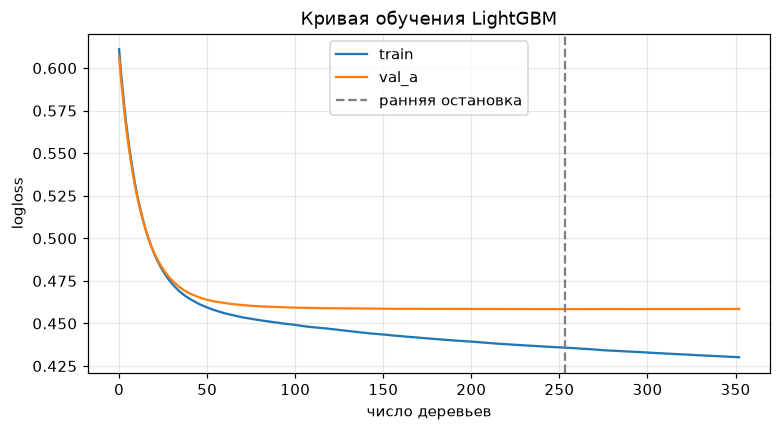

In [ ]:
display(LGB_PARAMS)
lgb_model, lgb_hist, lgb_time = train_lgb(X["train"], y["train"], X["val_a"], y["val_a"])
print(f"Деревьев (ранняя остановка): {lgb_model.best_iteration}; время обучения: {lgb_time:.0f} с; "
      f"пиковая память: {peak_ram_gb():.1f} ГБ")

plt.figure(figsize=(8, 4))
plt.plot(lgb_hist["train"]["binary_logloss"], label="train")
plt.plot(lgb_hist["val_a"]["binary_logloss"], label="val_a")
plt.axvline(lgb_model.best_iteration, color="gray", ls="--", label="ранняя остановка")
plt.xlabel("число деревьев")
plt.ylabel("logloss")
plt.legend()
plt.title("Кривая обучения LightGBM")
plt.show()

- за первые 50 деревьев - выучиваем основное
- val_a вызодит на плато
- чем глубде, тем больше деревья переобучались на train

## 6. Логистическая регрессия 

Вторая модель на тех же признаках
Отвечает на вопрос: **сколько качества даёт нелинейность бустинга** по сравнению с линейной моделью на тех же признаках
Предобработка:
-  log1p для счётчиков (у них длинный хвост)
- медиана + флаг для пропусков
- стандартизация

In [7]:
t0 = time.perf_counter()
lr_model = make_logreg(E0_FEATURES).fit(X["train"], y["train"])
lr_time = time.perf_counter() - t0
print(f"Время обучения: {lr_time:.0f} с; итераций: {lr_model[-1].n_iter_[0]}")

Время обучения: 24 с; итераций: 37


## 7. Метрики на val_a и val_b

**Две группы метрик отвечают на разные вопросы:**
- **LogLoss, ROC-AUC** — по всем строкам. В основном меряют, отличает ли модель пользователей, которые много дослушивают, от тех, кто много пропускает.
- **GAUC, NDCG, Recall** — внутри группы «пользователь × день». Меряют, правильно ли модель **упорядочивает треки для одного пользователя**. -Ю ТО ЧТО НАДО рек системе
  - GAUC — ROC-AUC внутри каждой группы, усреднённый по группам (0.5 = случайный порядок).

модель,часть,logloss,roc_auc,ndcg@10,recall@10,gauc,groups
str,str,f64,f64,f64,f64,f64,i64
"""константа""","""val_a""",0.6202,0.5,0.7101,0.4895,0.5,15808
"""случайный""","""val_a""",0.9637,0.4991,0.7093,0.4893,0.4989,15808
"""u_full_rate_30d""","""val_a""",0.4876,0.8058,0.7101,0.4895,0.5,15808
"""константа""","""val_b""",0.6114,0.5,0.7165,0.4859,0.5,15622
"""случайный""","""val_b""",0.9632,0.4999,0.7161,0.4858,0.5004,15622
"""u_full_rate_30d""","""val_b""",0.4812,0.8044,0.7165,0.4859,0.5,15622
"""LightGBM""","""val_a""",0.4584,0.8294,0.761,0.5143,0.574,15808
"""логрегрессия""","""val_a""",0.4688,0.8227,0.7526,0.511,0.5657,15808
"""LightGBM""","""val_b""",0.4558,0.8254,0.7651,0.5104,0.569,15622


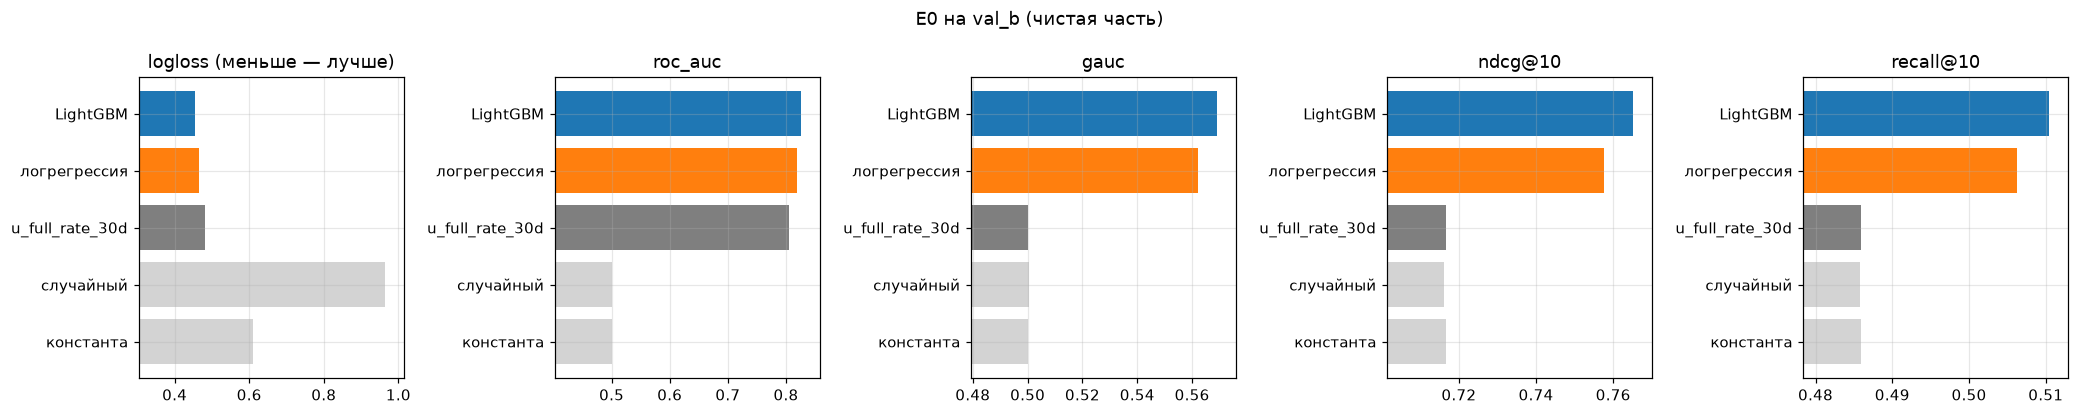

In [ ]:
rows = []
preds = []
for p in ["val_a", "val_b"]:
    d = parts[p].select("row_id", "uid", "day", "part", "label").with_columns(
        p_lgb=pl.Series(lgb_model.predict(X[p], num_iteration=lgb_model.best_iteration)),
        p_lr=pl.Series(lr_model.predict_proba(X[p])[:, 1]),
    )
    preds.append(d)
    
    for name, col in [("LightGBM", "p_lgb"), ("логрегрессия", "p_lr")]:
        rows.append({"модель": name, "часть": p, **evaluate(d, col)})

preds = pl.concat(preds)
metrics = pl.concat([baselines, pl.DataFrame(rows)])
display(metrics.with_columns(pl.col(c).round(4) for c in ["logloss", "roc_auc", "gauc", "ndcg@10", "recall@10"]))

fig, axes = plt.subplots(1, 5, figsize=(19, 3.8))
order = ["константа", "случайный", "u_full_rate_30d", "логрегрессия", "LightGBM"]
for ax, m in zip(axes, ["logloss", "roc_auc", "gauc", "ndcg@10", "recall@10"]):
    v = metrics.filter(pl.col("часть") == "val_b")
    vals = [v.filter(pl.col("модель") == o)[m].item() for o in order]
    ax.barh(order, vals, color=["lightgray", "lightgray", "tab:gray", "tab:orange", "tab:blue"])
    ax.set_title(m + (" (меньше — лучше)" if m == "logloss" else ""))
    lo = min(vals)
    hi = max(vals)
    ax.set_xlim(lo - (hi - lo) * 0.3, hi + (hi - lo) * 0.1)
    
plt.suptitle("E0 на val_b (чистая часть)")
plt.tight_layout()
plt.show()

- разница  небольшая
- пока что сами признаки играют большую роль
- возможно бустинг лучше получилось с пропускными значениям, ведь мы заполняли медианой и добавляли флаги нет истории

## 8. Сохранение результатов

сохраняем в `artifacts/E0/`:
- `results.pkl` — метрики, признаки, параметры, время и память, предсказания на val_a/val_b;
- `lgb.pkl`, `lr.pkl` — обученные модели.

In [9]:
results = {
    "experiment": "E0",
    "features": E0_FEATURES,
    "lgb_params": LGB_PARAMS,
    "best_iteration": lgb_model.best_iteration,
    "metrics": metrics,
    "predictions": preds,
    "cost": {"feature_time_s": feat_time, "lgb_train_s": lgb_time, "lr_train_s": lr_time,
             "peak_ram_gb": peak_ram_gb(), "n_features": len(E0_FEATURES)},
}
with open(ART / "results.pkl", "wb") as f:
    pickle.dump(results, f)
with open(ART / "lgb.pkl", "wb") as f:
    pickle.dump(lgb_model, f)
with open(ART / "lr.pkl", "wb") as f:
    pickle.dump(lr_model, f)
display(results["cost"])
print("Сохранено в", ART.relative_to(ROOT))

{'feature_time_s': 38.92474517000119,
 'lgb_train_s': 50.7644051949992,
 'lr_train_s': 23.925932991998707,
 'peak_ram_gb': 5.831092834472656,
 'n_features': 36}

Сохранено в artifacts/E0



## 9. Выводы



**Стоимость:** признаки — 39 с, LightGBM — ~51 с (253 дерева), логрегрессия — 24 с; пик памяти ноутбука ~5.8 ГБ 

### Главное наблюдение: «между пользователями» и «внутри пользователя» — две разные задачи
- **Один признак пользователя даёт 0.804 ROC-AUC из 0.825 у полной модели.** Основная часть «общего» качества — это умение отличить пользователя, который всё дослушивает, от того, кто всё пропускает 
- **Но внутри группы этот признак не делает ничего** (GAUC = 0.5): у всех треков пользователя за день он одинаков.
- **Ранжирование треков для одного пользователя — трудная задача:** GAUC всего 0.569, NDCG@10 растёт с 0.716 (случайный порядок) до 0.765.
  Рекомендательной системе нужно именно это качество, и в нём есть большой запас для улучшения

**Что это значит для исследования:** признаки, которые улучшают LogLoss/AUC, и признаки, которые улучшают ранжирование внутри пользователя, — не одно и то же. 

### Остальное
- **LightGBM лучше логрегрессии**, но ненамного -ручные признаки уже «упаковали» основную зависимость, а нелинейность даёт небольшой прирост 
- **Переобучения нет:** кривые train/val_a расходятся плавно, val_a выходит на плато к ~150 деревьям
- **val_a и val_b близки**  метрики стабильны во времени, подгонки под val_a не видно
- Пропуски в признаках — это отсутствие истории (например, `ui_days_since_last` пуст у 40% строк: трек пользователь раньше не слушал). LightGBM использует пропуск как отдельный сигнал
